# GNN Dataset Overview

**Project**: Identifying Pathogenic Significance Using AlphaFold 3D Structures  
**Model**: PAE-weighted GATv2 Graph Neural Network  
**Purpose**: Display every independent and dependent variable fed into the GNN.

⏱ **Estimated execution time: < 1 minute** — reads pre-built files from disk only, no model training.

---

In [1]:
import os, glob, warnings
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.float_format', '{:.4f}'.format)

BASE_DIR  = r"C:\Users\Megha Kanojia\Documents\DevProjects\agy2-projects\missense-variants"
GRAPH_DIR = os.path.join(BASE_DIR, "protein_graphs")
CSV_PATH  = os.path.join(BASE_DIR, "clinvar_graph_ready.csv")

print("Paths configured:")
print(f"  CSV found:        {os.path.exists(CSV_PATH)}")
print(f"  Graph dir found:  {os.path.isdir(GRAPH_DIR)}")
n_graphs = len(glob.glob(os.path.join(GRAPH_DIR, "*.pt")))
print(f"  Pre-built graphs: {n_graphs:,}")

Paths configured:
  CSV found:        True
  Graph dir found:  True
  Pre-built graphs: 6,597


---
## Section 1 — The Variant Dataset (rows × columns view)

Each row in this CSV is **one missense variant** — one training example for the GNN.  
The dataset was built from ClinVar (NCBI), filtered to 2-star+ independently reviewed variants only.

In [2]:
df = pd.read_csv(CSV_PATH)
print(f"Dataset shape: {df.shape[0]:,} variants  x  {df.shape[1]} columns\n")

# ── Column role table ─────────────────────────────────────────────────────────
col_info = [
    ('GeneSymbol',           'IDENTIFIER',       'Gene name (e.g. BRCA1) — human-readable protein identifier'),
    ('UniProt_ID',           'IDENTIFIER',       'UniProt accession — indexes the AlphaFold structure + ESM-2 embeddings'),
    ('Pos',                  'INPUT FEATURE',    'Position of the variant in the protein chain (1-indexed)'),
    ('Ref_AA',               'INPUT FEATURE',    'Wild-type amino acid normally found at this position'),
    ('Alt_AA',               'INPUT FEATURE',    'Mutant amino acid — what the disease mutation changed it to'),
    ('Target',               'OUTPUT (label)',   '0 = Benign  |  1 = Pathogenic    ← DEPENDENT VARIABLE'),
    ('ClinicalSignificance', 'METADATA',         'Original ClinVar text label (encoded into Target above)'),
    ('ReviewStatus',         'METADATA',         'Evidence quality — all rows are 2-star+ (independently confirmed)'),
    ('VariationID',          'METADATA',         'ClinVar unique variant ID (for traceability)'),
    ('Name',                 'METADATA',         'Full HGVS variant notation from ClinVar'),
]
role_df = pd.DataFrame(
    [(c, r, d) for c, r, d in col_info if c in df.columns],
    columns=['Column', 'Role', 'Description']
).set_index('Column')

print("Column roles:")
display(role_df)

Dataset shape: 49,303 variants  x  18 columns

Column roles:


,Role,Description
Column,,
GeneSymbol,IDENTIFIER,Gene name (e.g. BRCA1) — human-readable protein identifier
UniProt_ID,IDENTIFIER,UniProt accession — indexes the AlphaFold structure + ESM-2 embeddings
Pos,INPUT FEATURE,Position of the variant in the protein chain (1-indexed)
Ref_AA,INPUT FEATURE,Wild-type amino acid normally found at this position
Alt_AA,INPUT FEATURE,Mutant amino acid — what the disease mutation changed it to
Target,OUTPUT (label),0 = Benign | 1 = Pathogenic ← DEPENDENT VARIABLE
ClinicalSignificance,METADATA,Original ClinVar text label (encoded into Target above)
ReviewStatus,METADATA,Evidence quality — all rows are 2-star+ (independently confirmed)
VariationID,METADATA,ClinVar unique variant ID (for traceability)


In [3]:
# ── Sample rows ───────────────────────────────────────────────────────────────
view_cols = [c for c in ['GeneSymbol','UniProt_ID','Pos','Ref_AA','Alt_AA','Target','ClinicalSignificance'] if c in df.columns]

print("Sample rows (20 random variants):")
sample = df[view_cols].sample(20, random_state=7).reset_index(drop=True)
sample['Target_label'] = sample['Target'].map({0: 'Benign', 1: 'Pathogenic'})
display(sample)

# ── Class distribution ────────────────────────────────────────────────────────
print()
counts = df['Target'].value_counts().sort_index()
class_df = pd.DataFrame({
    'Label': ['Benign (0)', 'Pathogenic (1)'],
    'Count': [counts.get(0, 0), counts.get(1, 0)],
    'Percentage': [f"{counts.get(0,0)/len(df)*100:.1f}%", f"{counts.get(1,0)/len(df)*100:.1f}%"]
})
print("Class distribution:")
display(class_df.set_index('Label'))
print(f"\nUnique proteins (UniProt IDs): {df['UniProt_ID'].nunique():,}")
print(f"Unique genes (GeneSymbol):     {df['GeneSymbol'].nunique():,}")

Sample rows (20 random variants):


,GeneSymbol,UniProt_ID,Pos,Ref_AA,Alt_AA,Target,ClinicalSignificance,Target_label
0,FYCO1,Q9BQS8,339,Arg,Gln,0,Benign,Benign
1,FCSK,Q8N0W3,901,Arg,Trp,0,Benign/Likely benign,Benign
2,LDB3,O75112,349,Ser,Thr,0,Likely benign,Benign
3,SLC5A6,Q9Y289,189,Val,Ile,0,Likely benign,Benign
4,STRA6,Q9BX79,635,Gly,Ser,0,Benign/Likely benign,Benign
5,TK2,O00142,130,Arg,Trp,1,Pathogenic,Pathogenic
6,ARID1A,O14497,1016,Gly,Ser,0,Benign,Benign
7,HSPB1,P04792,60,Pro,Ser,0,Benign/Likely benign,Benign
8,NLRP7,Q8WX94,511,Lys,Arg,0,Benign,Benign
9,TNNT2,P45379,102,Arg,Trp,1,Pathogenic/Likely pathogenic,Pathogenic



Class distribution:


,Count,Percentage
Label,,
Benign (0),29152,59.1%
Pathogenic (1),20151,40.9%



Unique proteins (UniProt IDs): 6,597
Unique genes (GeneSymbol):     6,612


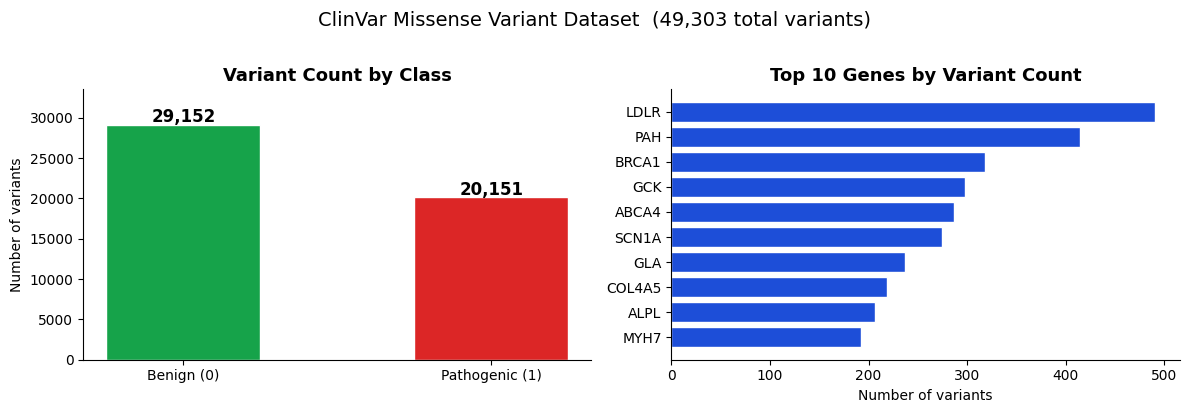

In [4]:
# ── Class distribution chart ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
ax = axes[0]
bars = ax.bar(['Benign (0)', 'Pathogenic (1)'],
               [counts.get(0,0), counts.get(1,0)],
               color=['#16a34a', '#dc2626'], width=0.5, edgecolor='white')
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 300, f'{h:,}', ha='center', fontsize=12, fontweight='bold')
ax.set_title('Variant Count by Class', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of variants')
ax.set_ylim(0, max(counts.values) * 1.15)
ax.spines[['top','right']].set_visible(False)

# Top 10 genes
ax2 = axes[1]
top10 = df.groupby('GeneSymbol')['Target'].count().sort_values(ascending=False).head(10)
colors = ['#1d4ed8'] * 10
ax2.barh(top10.index[::-1], top10.values[::-1], color=colors, edgecolor='white')
ax2.set_title('Top 10 Genes by Variant Count', fontsize=13, fontweight='bold')
ax2.set_xlabel('Number of variants')
ax2.spines[['top','right']].set_visible(False)

plt.suptitle(f'ClinVar Missense Variant Dataset  ({len(df):,} total variants)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---
## Section 2 — Feature Vectors: What the GNN Actually Receives

The GNN does **not** receive the CSV table directly.  
Each row of the CSV is converted into a **protein graph** where:

| Graph element | What it represents |
|---|---|
| **Node** | One amino acid residue in the protein chain |
| **Edge** | Two residues that are physically < 8 Å apart in the 3D structure |
| **Node features** | A 1,321-dimensional vector (see breakdown below) |
| **Edge features** | A 2-dimensional vector: distance + PAE confidence weight |

Only the **variant node** (the mutated residue) is read out for classification.  
All other nodes exist solely to pass structural context to the variant node via message passing.

In [5]:
# ── Node feature breakdown ────────────────────────────────────────────────────
AA_ORDER = ['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile',
            'Leu','Lys','Met','Phe','Pro','Ser','Thr','Trp','Tyr','Val']

node_feat_df = pd.DataFrame([
    {
        'Component':     '① ESM-2 Evolutionary Embedding',
        'Dimensions':    '0 – 1279',
        'Size':          1280,
        'Source':        'ESM-2 protein language model (650M params, trained on 250M sequences)',
        'What it encodes': (
            'Evolutionary context of this residue position across all known life. '
            'Captures conservation, co-evolution patterns, and functional importance. '
            'Computed once per protein and cached — the same 1280 numbers are shared '
            'across all variants in the same protein.'
        )
    },
    {
        'Component':     '② Wild-type amino acid (one-hot)',
        'Dimensions':    '1280 – 1299',
        'Size':          20,
        'Source':        'UniProt canonical sequence / AlphaFold metadata sequence',
        'What it encodes': (
            'Which of the 20 standard amino acids is normally found at this position. '
            f'One slot = 1, rest = 0. Amino acid order: {AA_ORDER}'
        )
    },
    {
        'Component':     '③ Variant-site flag',
        'Dimensions':    '1300',
        'Size':          1,
        'Source':        'ClinVar Pos field',
        'What it encodes': (
            '= 1 ONLY at the mutated residue (at position Pos-1 in the graph). '
            '= 0 at every other node in the graph. '
            'This tells the GNN exactly where the mutation occurred.'
        )
    },
    {
        'Component':     '④ Mutant amino acid (one-hot)',
        'Dimensions':    '1301 – 1320',
        'Size':          20,
        'Source':        'ClinVar Alt_AA field',
        'What it encodes': (
            'Which amino acid the mutation changed it to. '
            'All-zero at every non-variant node. '
            'Together with ③, tells the GNN what changed and where.'
        )
    },
    {
        'Component':     '── TOTAL ──',
        'Dimensions':    '',
        'Size':          1321,
        'Source':        '',
        'What it encodes': ''
    },
])
print("Node feature vector breakdown (1 vector per residue node):")
display(node_feat_df.set_index('Component'))

print()
print("IMPORTANT: Components ③ and ④ are zero for all non-variant nodes.")
print("           They are filled in per-variant at dataset load time (not stored on disk).")

Node feature vector breakdown (1 vector per residue node):


,Dimensions,Size,Source,What it encodes
Component,,,,
① ESM-2 Evolutionary Embedding,0 – 1279,1280,"ESM-2 protein language model (650M params, trained on 250M sequences)",Evolutionary context of this residue position across all known life. Capture...
② Wild-type amino acid (one-hot),1280 – 1299,20,UniProt canonical sequence / AlphaFold metadata sequence,Which of the 20 standard amino acids is normally found at this position. One...
③ Variant-site flag,1300,1,ClinVar Pos field,= 1 ONLY at the mutated residue (at position Pos-1 in the graph). = 0 at eve...
④ Mutant amino acid (one-hot),1301 – 1320,20,ClinVar Alt_AA field,Which amino acid the mutation changed it to. All-zero at every non-variant n...
── TOTAL ──,,1321,,



IMPORTANT: Components ③ and ④ are zero for all non-variant nodes.
           They are filled in per-variant at dataset load time (not stored on disk).


In [6]:
# ── Edge feature breakdown ────────────────────────────────────────────────────
edge_feat_df = pd.DataFrame([
    {
        'Component':     'Cα–Cα distance',
        'Dimension':     0,
        'Source':        'AlphaFold .pdb file (3D atomic coordinates)',
        'What it encodes': (
            'Physical distance in Ångströms (Å) between the alpha-carbon atoms '
            'of two residues in the folded protein. '
            'All edges have distance < 8 Å (the contact threshold used to build the graph).'
        )
    },
    {
        'Component':     'PAE-derived confidence weight',
        'Dimension':     1,
        'Source':        'AlphaFold Predicted Aligned Error .json file',
        'What it encodes': (
            '1 / (1 + PAE), where PAE = AlphaFold\'s own uncertainty in Å about the relative '
            'position of this residue pair. '
            'High confidence contact → PAE is low → weight near 0.5. '
            'Uncertain contact → PAE is high → weight near 0. '
            'This is the NOVEL CONTRIBUTION of this project: gMVP (prior work) treats all edges equally; '
            'we weight them by AlphaFold\'s own structural confidence.'
        )
    },
])
print("Edge feature vector breakdown (1 vector per contact pair):")
display(edge_feat_df.set_index('Component'))

Edge feature vector breakdown (1 vector per contact pair):


,Dimension,Source,What it encodes
Component,,,
Cα–Cα distance,0,AlphaFold .pdb file (3D atomic coordinates),Physical distance in Ångströms (Å) between the alpha-carbon atoms of two res...
PAE-derived confidence weight,1,AlphaFold Predicted Aligned Error .json file,"1 / (1 + PAE), where PAE = AlphaFold's own uncertainty in Å about the relati..."


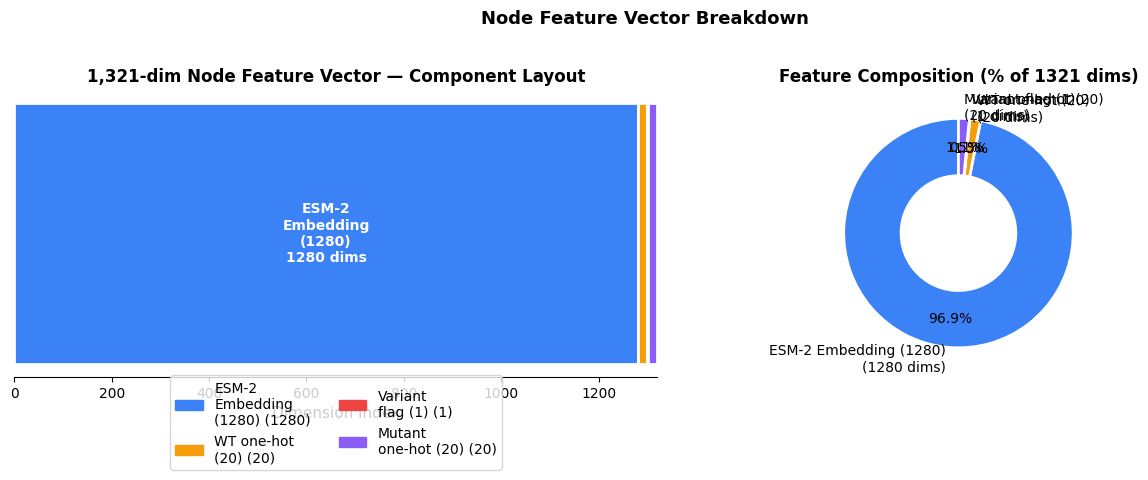

In [7]:
# ── Feature composition chart ─────────────────────────────────────────────────
components = ['ESM-2\nEmbedding\n(1280)', 'WT one-hot\n(20)', 'Variant\nflag (1)', 'Mutant\none-hot (20)']
sizes      = [1280, 20, 1, 20]
colors_bar = ['#3b82f6', '#f59e0b', '#ef4444', '#8b5cf6']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Stacked horizontal bar showing proportions
left = 0
for label, size, col in zip(components, sizes, colors_bar):
    ax1.barh([0], [size], left=left, color=col, edgecolor='white', linewidth=2, height=0.5)
    if size > 30:
        ax1.text(left + size/2, 0, f'{label}\n{size} dims', ha='center', va='center',
                 fontsize=10, fontweight='bold', color='white')
    left += size

ax1.set_xlim(0, 1321)
ax1.set_yticks([])
ax1.set_xlabel('Dimension index', fontsize=11)
ax1.set_title('1,321-dim Node Feature Vector — Component Layout', fontsize=12, fontweight='bold')
ax1.spines[['top','left','right']].set_visible(False)

patches = [mpatches.Patch(color=c, label=f'{l} ({s})') for l, s, c in zip(components, sizes, colors_bar)]
ax1.legend(handles=patches, loc='lower center', bbox_to_anchor=(0.5, -0.35), ncol=2, fontsize=10)

# Pie chart
wedge_props = dict(width=0.5, edgecolor='white', linewidth=2)
ax2.pie(sizes, labels=[f'{c.replace(chr(10)," ")}\n({s} dims)' for c,s in zip(components,sizes)],
        colors=colors_bar, autopct='%1.1f%%', startangle=90,
        wedgeprops=wedge_props, pctdistance=0.75, textprops={'fontsize': 10})
ax2.set_title('Feature Composition (% of 1321 dims)', fontsize=12, fontweight='bold')

plt.suptitle('Node Feature Vector Breakdown', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Section 3 — One Concrete Example (BRCA1 or First Available Protein)

Below we load an actual pre-built graph from disk and show:
1. The graph structure (nodes, edges, shapes)
2. The feature vector of the variant node, decomposed into its 4 components

In [8]:
# ── Load one example protein graph ────────────────────────────────────────────
preferred = os.path.join(GRAPH_DIR, "P38398.pt")   # BRCA1
if os.path.exists(preferred):
    graph_path = preferred
    prot_id    = "P38398"
    gene       = "BRCA1"
else:
    all_graphs = sorted(glob.glob(os.path.join(GRAPH_DIR, "*.pt")))
    graph_path = all_graphs[0]
    prot_id    = os.path.basename(graph_path).replace('.pt', '')
    gene_match = df[df['UniProt_ID'] == prot_id]['GeneSymbol']
    gene       = gene_match.iloc[0] if len(gene_match) else 'Unknown'

graph = torch.load(graph_path, weights_only=False)

n_nodes      = graph.x.shape[0]
n_edges      = graph.edge_index.shape[1]
node_dim     = graph.x.shape[1]
edge_dim     = graph.edge_attr.shape[1]
n_contacts   = n_edges // 2

print(f"── Example graph: {gene} ({prot_id}) ──\n")
print(f"  Protein chain length (residues):  {n_nodes:,}  →  {n_nodes:,} nodes in the graph")
print(f"  Node feature vector size:         {node_dim}  (the 1321-dim vector)")
print(f"  Contact pairs within 8 Å:         {n_contacts:,}  →  {n_edges:,} directed edges")
print(f"  Edge feature vector size:         {edge_dim}  (distance + PAE weight)")
print()

dist_vals   = graph.edge_attr[:, 0]
pae_weights = graph.edge_attr[:, 1]
print("  Edge attribute statistics:")
print(f"    Cα distance (Å):     min={dist_vals.min():.2f}  median={dist_vals.median():.2f}  max={dist_vals.max():.2f}")
print(f"    PAE weight:          min={pae_weights.min():.4f}  median={pae_weights.median():.4f}  max={pae_weights.max():.4f}")
print()
print("  Average contacts per residue:", f"{n_contacts/n_nodes:.1f}")
print(f"\n  graph.x shape:           {tuple(graph.x.shape)}    ← [num_nodes, 1321]")
print(f"  graph.edge_index shape:  {tuple(graph.edge_index.shape)}    ← [2, num_edges]")
print(f"  graph.edge_attr shape:   {tuple(graph.edge_attr.shape)}    ← [num_edges, 2]")

── Example graph: BRCA1 (P38398) ──

  Protein chain length (residues):  1,863  →  1,863 nodes in the graph
  Node feature vector size:         1321  (the 1321-dim vector)
  Contact pairs within 8 Å:         4,930  →  9,860 directed edges
  Edge feature vector size:         2  (distance + PAE weight)

  Edge attribute statistics:
    Cα distance (Å):     min=3.01  median=5.65  max=8.00
    PAE weight:          min=0.0317  median=0.4000  max=0.5000

  Average contacts per residue: 2.6

  graph.x shape:           (1863, 1321)    ← [num_nodes, 1321]
  graph.edge_index shape:  (2, 9860)    ← [2, num_edges]
  graph.edge_attr shape:   (9860, 2)    ← [num_edges, 2]


In [9]:
# ── Show the variant node's feature vector, decomposed ─────────────────────────
AA_ORDER = ['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile',
            'Leu','Lys','Met','Phe','Pro','Ser','Thr','Trp','Tyr','Val']
AA_IDX   = {aa: i for i, aa in enumerate(AA_ORDER)}

# Pick one variant from this protein
prot_variants = df[df['UniProt_ID'] == prot_id]
if len(prot_variants) == 0:
    print(f"No variants found for {prot_id} in the CSV — picking a random node for demo.")
    example = df.iloc[0]
    example_prot_id = example['UniProt_ID']
    graph = torch.load(os.path.join(GRAPH_DIR, f"{example_prot_id}.pt"), weights_only=False)
    node_idx = int(example['Pos']) - 1
else:
    # Prefer a Pathogenic variant for illustration
    path_vars = prot_variants[prot_variants['Target'] == 1]
    example   = path_vars.iloc[0] if len(path_vars) > 0 else prot_variants.iloc[0]
    node_idx  = int(example['Pos']) - 1

ref_aa  = example['Ref_AA']
alt_aa  = example['Alt_AA']
pos     = int(example['Pos'])
gene_ex = example['GeneSymbol']
target  = 'Pathogenic' if example['Target'] == 1 else 'Benign'

# The base graph has zeros in dims 1300-1320; apply variant edits here for display
x_base    = graph.x[node_idx].clone()      # as stored on disk
x_variant = x_base.clone()                 # what the dataset returns after applying edits
x_variant[1300] = 1.0
alt_idx = AA_IDX.get(alt_aa, -1)
if alt_idx >= 0:
    x_variant[1301 + alt_idx] = 1.0

wt_idx = x_base[1280:1300].argmax().item()

print(f"── Variant node feature vector: {gene_ex} {ref_aa}{pos}{alt_aa} ({target}) ──\n")
print(f"  Node index in graph: {node_idx}  (= Pos {pos} − 1, because Python is 0-indexed)\n")

print("  Component ①  ESM-2 embedding  (dims 0 – 1279):")
print(f"    Shape:   ({x_variant[:1280].shape[0]},)")
print(f"    First 8: {x_variant[:8].numpy().round(4).tolist()}")
print(f"    Mean={x_variant[:1280].mean():.4f}   Std={x_variant[:1280].std():.4f}")
print(f"    Interpretation: high std → this position is evolutionarily distinctive\n")

print("  Component ②  Wild-type one-hot  (dims 1280 – 1299):")
wt_vec = x_variant[1280:1300].numpy().astype(int).tolist()
print(f"    Vector: {wt_vec}")
print(f"    Active index: {wt_idx}  →  amino acid = {AA_ORDER[wt_idx]}  (= {ref_aa})\n")

print("  Component ③  Variant-site flag  (dim 1300):")
print(f"    Value: {x_variant[1300].item():.0f}  ← 1 means this node IS the mutation site\n")

print("  Component ④  Mutant amino acid one-hot  (dims 1301 – 1320):")
alt_vec = x_variant[1301:1321].numpy().astype(int).tolist()
print(f"    Vector: {alt_vec}")
if alt_idx >= 0:
    print(f"    Active index: {alt_idx}  →  amino acid = {AA_ORDER[alt_idx]}  (= {alt_aa})")
print(f"\n  TOTAL dimensions: {x_variant.shape[0]}")

── Variant node feature vector: BRCA1 Cys64Gly (Pathogenic) ──

  Node index in graph: 63  (= Pos 64 − 1, because Python is 0-indexed)

  Component ①  ESM-2 embedding  (dims 0 – 1279):
    Shape:   (1280,)
    First 8: [-0.24459999799728394, -0.4339999854564667, -0.05739999935030937, 0.45910000801086426, 0.13510000705718994, 0.0982000008225441, 0.30300000309944153, -0.094200000166893]
    Mean=0.0002   Std=0.2617
    Interpretation: high std → this position is evolutionarily distinctive

  Component ②  Wild-type one-hot  (dims 1280 – 1299):
    Vector: [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
    Active index: 1  →  amino acid = Arg  (= Cys)

  Component ③  Variant-site flag  (dim 1300):
    Value: 1  ← 1 means this node IS the mutation site

  Component ④  Mutant amino acid one-hot  (dims 1301 – 1320):
    Vector: [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
    Active index: 7  →  amino acid = Gly  (= Gly)

  TOTAL dimensions: 1321


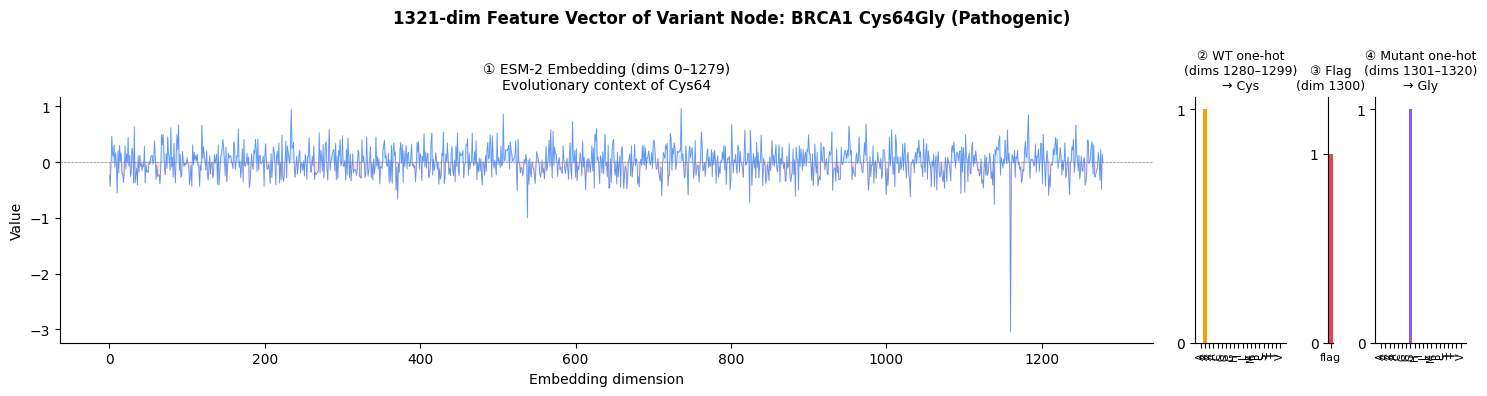

In [10]:
# ── Visual: feature vector values across all 1321 dimensions ──────────────────
fig, axes = plt.subplots(1, 4, figsize=(15, 4),
                         gridspec_kw={'width_ratios': [12, 1, 0.05, 1]})

# Panel 1: ESM-2 embedding (1280 dims)
ax = axes[0]
esm_vals = x_variant[:1280].numpy()
ax.plot(range(1280), esm_vals, color='#3b82f6', linewidth=0.6, alpha=0.8)
ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
ax.fill_between(range(1280), esm_vals, 0,
                where=(esm_vals > 0), color='#3b82f6', alpha=0.15)
ax.fill_between(range(1280), esm_vals, 0,
                where=(esm_vals < 0), color='#ef4444', alpha=0.15)
ax.set_title(f'① ESM-2 Embedding (dims 0–1279)\nEvolutionary context of {ref_aa}{pos}',
             fontsize=10)
ax.set_xlabel('Embedding dimension')
ax.set_ylabel('Value')
ax.spines[['top','right']].set_visible(False)

# Panel 2: WT one-hot
ax2 = axes[1]
wt_vec_arr = x_variant[1280:1300].numpy()
bars = ax2.bar(range(20), wt_vec_arr, color=['#f59e0b' if i==wt_idx else '#e5e7eb' for i in range(20)])
ax2.set_xticks(range(20))
ax2.set_xticklabels([aa[:1] for aa in AA_ORDER], fontsize=7, rotation=90)
ax2.set_title(f'② WT one-hot\n(dims 1280–1299)\n→ {ref_aa}', fontsize=9)
ax2.set_yticks([0, 1])
ax2.spines[['top','right']].set_visible(False)

# Panel 3: flag
ax3 = axes[2]
ax3.bar([0], [x_variant[1300].item()], color='#ef4444', width=0.6)
ax3.set_xticks([0])
ax3.set_xticklabels(['flag'], fontsize=8)
ax3.set_title(f'③ Flag\n(dim 1300)', fontsize=9)
ax3.set_ylim(0, 1.3)
ax3.set_yticks([0, 1])
ax3.spines[['top','right']].set_visible(False)

# Panel 4: Alt one-hot
ax4 = axes[3]
alt_vec_arr = x_variant[1301:1321].numpy()
ax4.bar(range(20), alt_vec_arr, color=['#8b5cf6' if i==alt_idx else '#e5e7eb' for i in range(20)])
ax4.set_xticks(range(20))
ax4.set_xticklabels([aa[:1] for aa in AA_ORDER], fontsize=7, rotation=90)
ax4.set_title(f'④ Mutant one-hot\n(dims 1301–1320)\n→ {alt_aa}', fontsize=9)
ax4.set_yticks([0, 1])
ax4.spines[['top','right']].set_visible(False)

plt.suptitle(f'1321-dim Feature Vector of Variant Node: {gene_ex} {ref_aa}{pos}{alt_aa} ({target})',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Section 4 — Dataset Summary Statistics

In [11]:
# ── Full dataset statistics ────────────────────────────────────────────────────
n_path = int((df['Target'] == 1).sum())
n_ben  = int((df['Target'] == 0).sum())

summary = pd.DataFrame([
    ('Total variants',                       f"{len(df):,}"),
    ('  of which Pathogenic (Target=1)',      f"{n_path:,}  ({n_path/len(df)*100:.1f}%)"),
    ('  of which Benign    (Target=0)',       f"{n_ben:,}  ({n_ben/len(df)*100:.1f}%)"),
    ('Unique proteins (UniProt IDs)',         f"{df['UniProt_ID'].nunique():,}"),
    ('Unique genes (GeneSymbol)',             f"{df['GeneSymbol'].nunique():,}"),
    ('Source database',                      'ClinVar (NCBI), filtered to 2-star+ reviewed variants only'),
    ('─── Graph structure ───',              ''),
    ('Node feature dimensions',              '1,321  per node  (1280 ESM-2 + 20 WT + 1 flag + 20 Alt)'),
    ('Edge feature dimensions',              '2  per edge  (Cα distance + PAE weight)'),
    ('Edge connection threshold',            '< 8 Å Cα–Cα distance in AlphaFold structure'),
    ('─── Train / Val / Test split ───',     ''),
    ('Split strategy',                       'Protein-level (by UniProt_ID) — same protein never in both train and test'),
    ('Split ratio',                          '70% train  /  15% validation  /  15% test'),
    ('Training variants',                    '~34,732  (approx.)'),
    ('─── Model ───',                        ''),
    ('Architecture',                         'PAE-weighted GATv2 (2 layers, 4 attention heads, hidden_dim=128)'),
    ('Readout',                              'Variant node only  →  MLP(128 → 64 → 1)  →  sigmoid'),
    ('Primary metric',                       'AUPRC (Area Under Precision-Recall Curve)'),
    ('Baseline comparisons',                 'GATv2-unweighted, GCN, GraphSAGE, XGBoost'),
], columns=['Item', 'Value'])

display(summary.set_index('Item').style.set_properties(
    **{'text-align': 'left', 'white-space': 'pre-wrap'}
))

,Value
Item,
Total variants,"49,303"
of which Pathogenic (Target=1),"20,151 (40.9%)"
of which Benign (Target=0),"29,152 (59.1%)"
Unique proteins (UniProt IDs),"6,597"
Unique genes (GeneSymbol),"6,612"
Source database,"ClinVar (NCBI), filtered to 2-star+ reviewed variants only"
─── Graph structure ───,
Node feature dimensions,"1,321 per node (1280 ESM-2 + 20 WT + 1 flag + 20 Alt)"
Edge feature dimensions,2 per edge (Cα distance + PAE weight)


Loading 200 sample graphs to estimate size distribution... done.


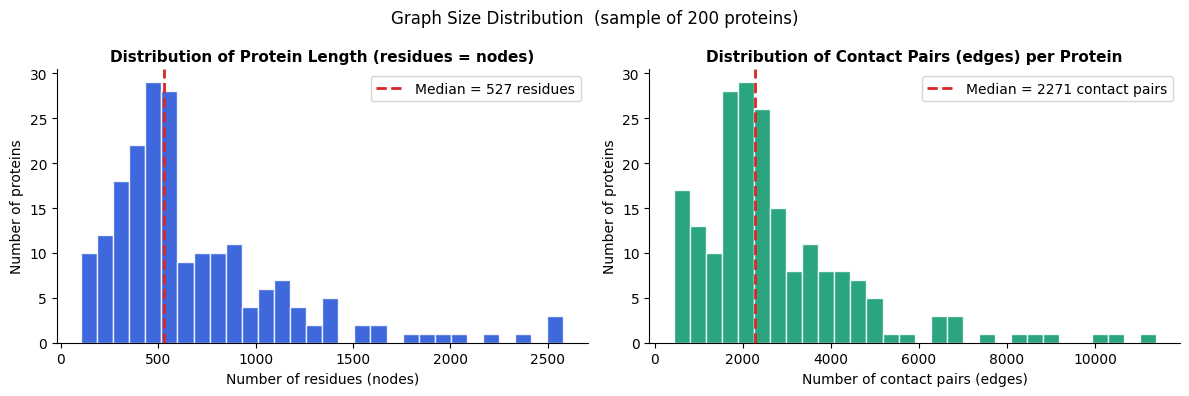

Nodes (residues) per protein:  median=527,  mean=684,  max=2581
Edges (contacts) per protein:  median=2271,  mean=2752,  max=11385


In [12]:
# ── Graph size distribution (sample 200 proteins to keep it fast) ──────────────
all_graphs  = sorted(glob.glob(os.path.join(GRAPH_DIR, "*.pt")))
sample_size = min(200, len(all_graphs))
rng         = np.random.default_rng(42)
sample_paths = rng.choice(all_graphs, size=sample_size, replace=False)

print(f"Loading {sample_size} sample graphs to estimate size distribution...", end=" ", flush=True)
n_nodes_list, n_edges_list = [], []
for p in sample_paths:
    g = torch.load(p, weights_only=False)
    n_nodes_list.append(g.x.shape[0])
    n_edges_list.append(g.edge_index.shape[1] // 2)
print("done.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(n_nodes_list, bins=30, color='#1d4ed8', edgecolor='white', alpha=0.85)
axes[0].axvline(np.median(n_nodes_list), color='#dc2626', linewidth=2, linestyle='--',
                label=f'Median = {int(np.median(n_nodes_list))} residues')
axes[0].set_title('Distribution of Protein Length (residues = nodes)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Number of residues (nodes)')
axes[0].set_ylabel('Number of proteins')
axes[0].legend()
axes[0].spines[['top','right']].set_visible(False)

axes[1].hist(n_edges_list, bins=30, color='#059669', edgecolor='white', alpha=0.85)
axes[1].axvline(np.median(n_edges_list), color='#dc2626', linewidth=2, linestyle='--',
                label=f'Median = {int(np.median(n_edges_list))} contact pairs')
axes[1].set_title('Distribution of Contact Pairs (edges) per Protein', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Number of contact pairs (edges)')
axes[1].set_ylabel('Number of proteins')
axes[1].legend()
axes[1].spines[['top','right']].set_visible(False)

plt.suptitle(f'Graph Size Distribution  (sample of {sample_size} proteins)', fontsize=12)
plt.tight_layout()
plt.show()

print(f"Nodes (residues) per protein:  median={int(np.median(n_nodes_list))},  "
      f"mean={np.mean(n_nodes_list):.0f},  max={max(n_nodes_list)}")
print(f"Edges (contacts) per protein:  median={int(np.median(n_edges_list))},  "
      f"mean={np.mean(n_edges_list):.0f},  max={max(n_edges_list)}")

---
## Summary for Supervisor

### Independent variables (features fed to the GNN)

| # | Feature | Dimensions | Source | Role in model |
|---|---|---|---|---|
| ① | ESM-2 evolutionary embedding | 1280 / node | ESM-2 650M protein language model | Captures conservation and functional importance of each residue |
| ② | Wild-type amino acid (one-hot) | 20 / node | UniProt canonical sequence | Tells the model which amino acid is normally here |
| ③ | Variant-site flag | 1 / node | ClinVar `Pos` | Marks exactly which node was mutated |
| ④ | Mutant amino acid (one-hot) | 20 / node | ClinVar `Alt_AA` | Tells the model what the mutation changed it to |
| ⑤ | Cα–Cα distance | 1 / edge | AlphaFold `.pdb` 3D coordinates | Encodes how physically close two residues are |
| ⑥ | PAE confidence weight | 1 / edge | AlphaFold PAE `.json` | Weights each structural contact by AlphaFold's own confidence |

**Total per node: 1,321 dimensions.  Total per edge: 2 dimensions.**

### Dependent variable

| Variable | Values | Source |
|---|---|---|
| `Target` | 0 = Benign, 1 = Pathogenic | ClinVar clinical significance, 2-star+ reviewed |

### Why a graph — not a table?

A flat table could hold only the variant's own features (columns ①–④).  
The graph additionally encodes **which residues are physically nearby in 3D space** (edges ⑤–⑥).  
After two rounds of PAE-weighted message passing, the variant node's embedding contains  
not just its own identity but also the structural context of its neighbourhood —  
information that is invisible in any sequence-based representation.